1. Import the necessary packages

In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

## 2. Load Dataset

Column index mapping used in `df.iloc` selection:

| Column | Index |
|--------|-------|
| ID | 1 |
| age | 9 |
| ho_incm | 12 |
| edu | 15 |
| BD1 | 232 |
| BD1_11 | 234 |
| BM7 | 520 |
| BM14 | 535 |
| O_TC | 496 |
| BS1_1 | 300 |


> 

**Note:** `BS1_1` (index 300) is included here temporarily to evaluate its NaN rate as a candidate replacement for `BS3_1` and `BS3_2`.


In [4]:
df = pd.read_csv('KNHANES9.csv') 

df_subset = (df.iloc[:, [1, 9, 12, 15, 232, 234, 300, 520, 535, 496]])
age_threshold = 50 
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.head(1))

           ID  age ho_incm edu BD1 BD1_11 BS1_1 BM7 BM14 O_TC
5  WA01264601   80       1   1   1      8     3   2    1   23


## 3. Target Variable Cleaning & Label Creation

This step cleans the `O_TC` (total tooth count) column and produces a binary classification label:

- **a.** Invalid entries stored as `-1.80E+308` are treated as `NaN` in the raw dataset
- **b.** `errors='coerce'` converts any non-numeric values (including `-1.80E+308`) to `NaN`
- **c.** Rows where `O_TC` is `NaN` are dropped, keeping only records with a valid tooth count
- **d.** A binary label column `O_TC_` is created: `1` if tooth count < 20, `0` otherwise (`astype(int)` maps `True` → 1 and `False` → 0)
- **e.** `label_counts` tallies the number of records in each class (0 or 1)


In [5]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows droppped (NaN O_TC): {before_drop - len(df_subset)}")

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)

label_counts    = df_subset['O_TC_'].value_counts()
label_0         = label_counts[0]
label_1         = label_counts[1]
imbalance_ratio = label_0 / label_1

print(f"Age filter: >= {age_threshold}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(20))
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

['-1.80E+308']
Rows droppped (NaN O_TC): 410
Age filter: >= 50
Label 0 (≥20 teeth): 2441
Label 1 (<20 teeth): 894
O_TC
28.0    556
27.0    350
26.0    283
25.0    188
0.0     179
24.0    179
23.0    166
32.0    132
29.0    128
21.0    114
22.0    112
30.0     95
20.0     89
19.0     67
16.0     59
17.0     53
18.0     49
31.0     49
15.0     41
12.0     39
Name: count, dtype: int64
Imbalance ratio: 2.73
NaN count: 0


4. Missing Value Audit 

In [6]:
invalid_codes = [8, 9, 88, 99, 888, 999, 8888, 9999]
feature_cols  = ['age', 'ho_incm', 'edu', 'BD1', 'BD1_11', 'BS1_1', 'BM7', 'BM14']


df_subset[feature_cols] = df_subset[feature_cols].replace(invalid_codes, np.nan)
df_subset[feature_cols] = df_subset[feature_cols].apply(pd.to_numeric, errors='coerce')
df_subset[feature_cols] = df_subset[feature_cols].where(df_subset[feature_cols].abs() < 1e10, np.nan)

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in feature_cols:
    count = df_subset[col].isna().sum()
    pct = (count/total) * 100 
    print(f"{col}: {count} | ({pct:.1f}%)")




NaN counts per column after cleaning:
age: 0 | (0.0%)
ho_incm: 22 | (0.7%)
edu: 137 | (4.1%)
BD1: 49 | (1.5%)
BD1_11: 205 | (6.1%)
BS1_1: 49 | (1.5%)
BM7: 49 | (1.5%)
BM14: 49 | (1.5%)


### High NaN Count: BS3_1 & BS3_2

`BS3_1` and `BS3_2` have an extraordinarily high proportion of missing values, making them unusable for model training. Imputation is not viable at this level of missingness, so these features will be dropped and replaced with an alternative smoking-related variable.

The table below shows NaN rates for other available smoking-related features:


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df_subset[['age', 'ho_incm', 'edu', 'BD1', 'BD1_11', 'BS1_1', 'BM7', 'BM14']]
y = df_subset['O_TC_']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test  = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

X_train: (2668, 8), X_test: (667, 8)


### 6. SimpleImputer 


In [8]:
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test  = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

### 7. Standardization 

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# For Logistic Regression and SVM — normalize all features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# For RF, XGBoost, LightGBM — NO standardization needed
X_train_tree = X_train.copy()
X_test_tree  = X_test.copy()

### 8. Class Imbalance -- using SMOTE (1/1.5 ratio)

In [10]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy = 1/1.5, k_neighbors=5, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("After SMOTE: ", pd.Series(y_train_resampled).value_counts().to_dict())

Before SMOTE: {0: 1953, 1: 715}
After SMOTE:  {0: 1953, 1: 1302}


### Hyperparameter Tuning

**Method:** RandomizedSearchCV (faster than GridSearch for 5 models; 50 iterations per model, `scoring = 'roc_auc'`)

| Model                   | Key Hyperparameters                                                | Tuning Range                                     |
| :---------------------- | :----------------------------------------------------------------- | :----------------------------------------------- |
| **Random Forest**       | `n_estimators`, `max_depth`, `min_samples_leaf`                    | 100/300/500 · 5/10/15/None · 1/5/10              |
| **XGBoost**             | `n_estimators`, `max_depth`, `learning_rate`, `subsample`          | 100/300/500 · 3/5/7 · 0.01/0.1/0.3 · 0.7/0.8/1.0 |
| **LightGBM**            | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples` | 100/300/500 · 15/31/63 · 0.01/0.1/0.3 · 5/10/20  |
| **Logistic Regression** | `C`, `penalty`                                                     | 0.01/0.1/1/10 · L1/L2                            |
| **SVM**                 | `C`, `kernel`, `gamma`                                             | 0.1/1/10 · rbf/linear · scale/auto               |

In [11]:
import sys
!{sys.executable} -m pip install xgboost


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [12]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import pandas as pd

param_grids = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators':     [100, 300, 500],
            'max_depth':        [5, 10, 15, None],
            'min_samples_leaf': [1, 5, 10]
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'),
        'params': {
            'n_estimators':  [100, 300, 500],
            'max_depth':     [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.3],
            'subsample':     [0.7, 0.8, 1.0]
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(random_state=42),
        'params': {
            'n_estimators':     [100, 300, 500],
            'num_leaves':       [15, 31, 63],
            'learning_rate':    [0.01, 0.1, 0.3],
            'min_child_samples':[5, 10, 20]
        }
    },
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000, solver='saga'),
        'params': {
            'C':       [0.01, 0.1, 1, 10],
            'penalty': ['l1', 'l2']
        }
    },
    'SVM': {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'C':      [0.1, 1, 10],
            'kernel': ['rbf', 'linear'],
            'gamma':  ['scale', 'auto']
        }
    }
}

cv      = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, config in param_grids.items():
    search = RandomizedSearchCV(
        estimator          = config['model'],
        param_distributions= config['params'],
        n_iter             = 50,
        cv                 = cv,
        scoring            = 'roc_auc',
        random_state       = 42,
        n_jobs             = -1
    )
    search.fit(X_train_resampled, y_train_resampled)
    results[name] = {
        'best_params':    search.best_params_,
        'best_cv_score':  search.best_score_
    }
    print(f"{name}: Best AUC = {search.best_score_:.4f} | Params: {search.best_params_}")

# Print comparison table ranked by AUC
results_df = pd.DataFrame(
    {name: {'AUC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUC', ascending=False)
print(results_df)

Random Forest: Best AUC = 0.8697 | Params: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_depth': 10}
XGBoost: Best AUC = 0.8741 | Params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}
[LightGBM] [Info] Number of positive: 1041, number of negative: 1563
[LightGBM] [Info] Number of positive: 1042, number of negative: 1562
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008361 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006859 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 462
[LightGBM] [Info] Total Bins 490
[LightGBM] [Info] Number of data points in the train set: 2604, number of used features: 8
[LightGBM] [Info] Number of data points in the train set: 2604, number of used features: 8
[Light

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warni

Logistic Regression: Best AUC = 0.7906 | Params: {'penalty': 'l2', 'C': 0.1}
SVM: Best AUC = 0.8190 | Params: {'kernel': 'rbf', 'gamma': 'auto', 'C': 10}
                          AUC
XGBoost              0.874129
LightGBM             0.872094
Random Forest        0.869729
SVM                  0.818993
Logistic Regression  0.790563


### 5. PyCaret Model Screening → Top 3 Models (Criterion: AUC)

#### 5.1 PyCaret Setup & Screening

In [30]:
corr = df_subset.drop(columns=['O_TC', 'ID']).corr(numeric_only=True)['O_TC_'].drop('O_TC_').sort_values()
print(corr)


edu       -0.304874
ho_incm   -0.281796
BM7       -0.099618
BS1_1      0.071150
BD1        0.071172
BD1_11     0.084903
BM14       0.112553
age        0.413456
Name: O_TC_, dtype: float64


In [24]:
from pycaret.classification import *

# Setup
clf = setup(
    data = df_subset.drop(columns=['O_TC']),
    target = 'O_TC_',
    fix_imbalance = True,          # SMOTE equivalent in PyCaret
    normalize = True,             # for LR and SVM
    fold = 5,                # stratified 5-fold CV
    fold_strategy = 'stratifiedkfold',
    session_id = 42
)

# Screen all models
best_models = compare_models(sort='AUC', n_select=3)

,Description,Value
0,Session id,42
1,Target,O_TC_
2,Target type,Binary
3,Original data shape,"(3335, 10)"
4,Transformed data shape,"(4417, 10)"
5,Transformed train set shape,"(3416, 10)"
6,Transformed test set shape,"(1001, 10)"
7,Numeric features,8
8,Categorical features,1
9,Rows with missing values,9.0%


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,0.7318,0.7919,0.0000,0.0000,0.0000,0.0000,0.0000,0.0220
lr,Logistic Regression,0.7318,0.7887,0.0000,0.0000,0.0000,0.0000,0.0000,0.8380
lightgbm,Light Gradient Boosting Machine,0.7318,0.6945,0.0000,0.0000,0.0000,0.0000,0.0000,0.0800
svm,SVM - Linear Kernel,0.6556,0.6519,0.3008,0.1406,0.1881,0.0663,0.0824,0.0260
rf,Random Forest Classifier,0.7318,0.6262,0.0000,0.0000,0.0000,0.0000,0.0000,0.0460
lda,Linear Discriminant Analysis,0.7159,0.5518,0.1376,0.0823,0.1030,0.0541,0.0585,0.0380
knn,K Neighbors Classifier,0.7322,0.5102,0.0032,0.3000,0.0063,0.0038,0.0221,0.3640
nb,Naive Bayes,0.7318,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3280
dt,Decision Tree Classifier,0.7318,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3320
ada,Ada Boost Classifier,0.7318,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0120


In [18]:
best_models = compare_models(sort='AUC', n_select=3)


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.7824,1.0000,0.1885,1.0000,0.3113,0.2511,0.3745,0.0500
ada,Ada Boost Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0140
gbc,Gradient Boosting Classifier,0.7318,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0360
ridge,Ridge Classifier,0.7318,0.9990,0.0000,0.0000,0.0000,0.0000,0.0000,0.0160
lr,Logistic Regression,0.8603,0.9978,0.4792,1.0000,0.6473,0.5735,0.6341,0.7880
et,Extra Trees Classifier,0.7862,0.9901,0.2030,1.0000,0.3260,0.2663,0.3855,0.0360
svm,SVM - Linear Kernel,0.8728,0.9735,0.5467,0.9803,0.6673,0.6055,0.6620,0.0180
knn,K Neighbors Classifier,0.8612,0.7993,0.4824,1.0000,0.6503,0.5766,0.6366,0.3200
lightgbm,Light Gradient Boosting Machine,0.7318,0.7796,0.0000,0.0000,0.0000,0.0000,0.0000,0.0860
lda,Linear Discriminant Analysis,0.7798,0.5998,0.1792,0.2000,0.1890,0.1853,0.1858,0.0260


### 10. Visualization

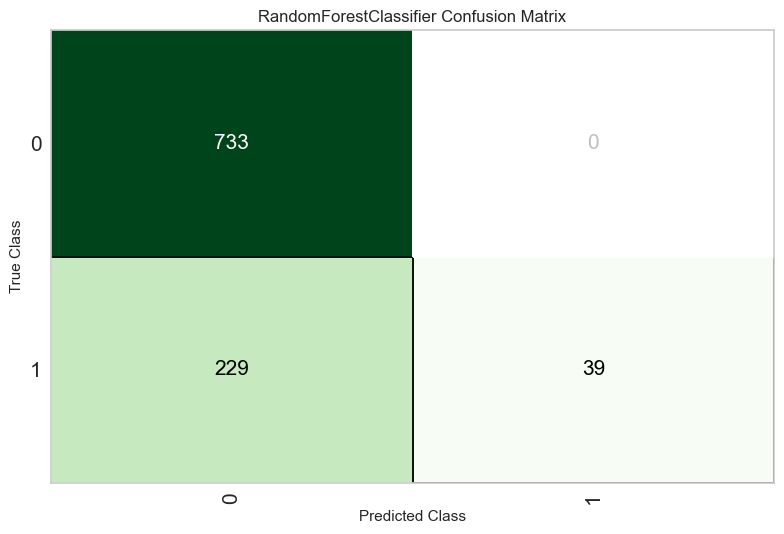

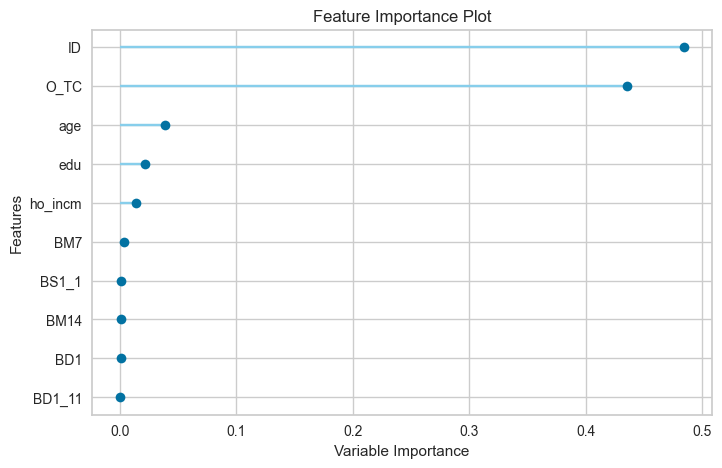

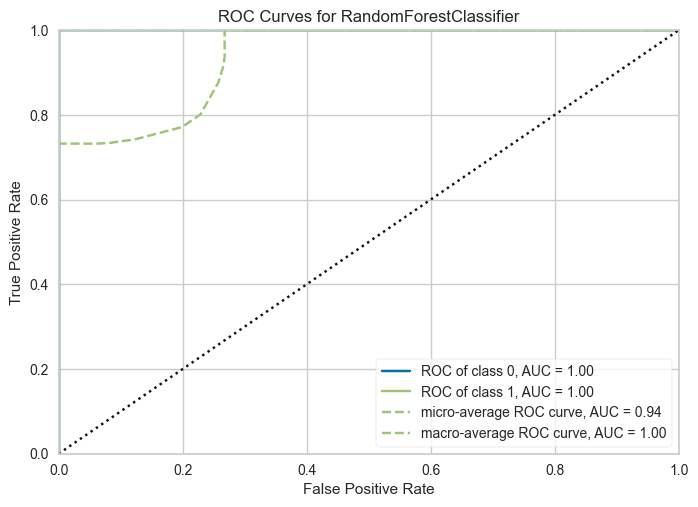

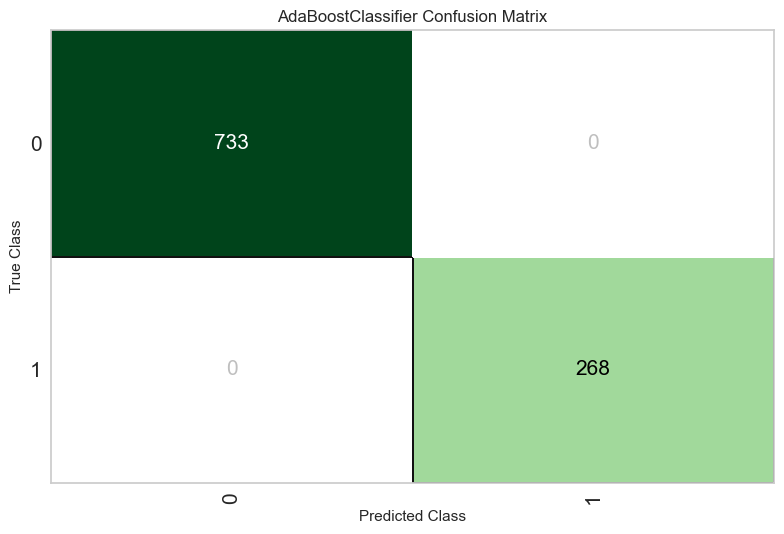

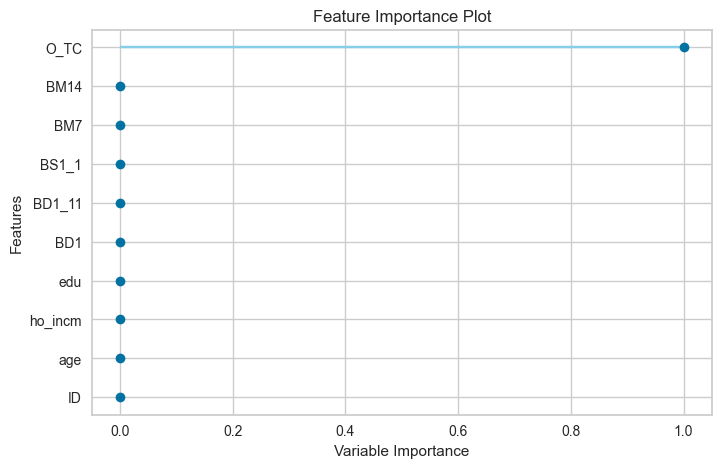

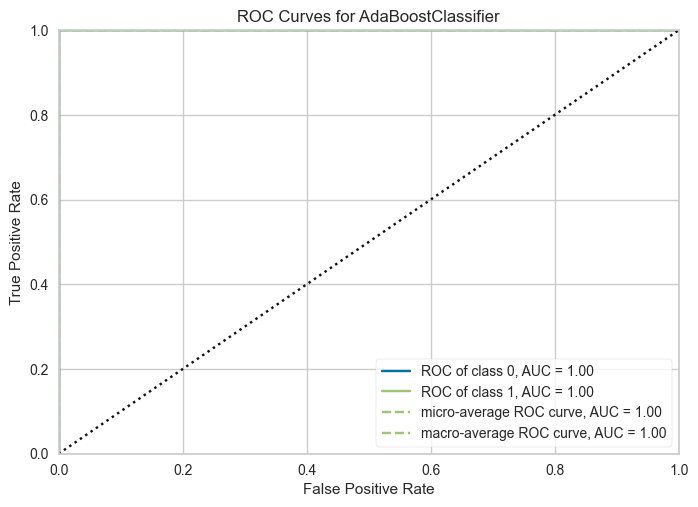

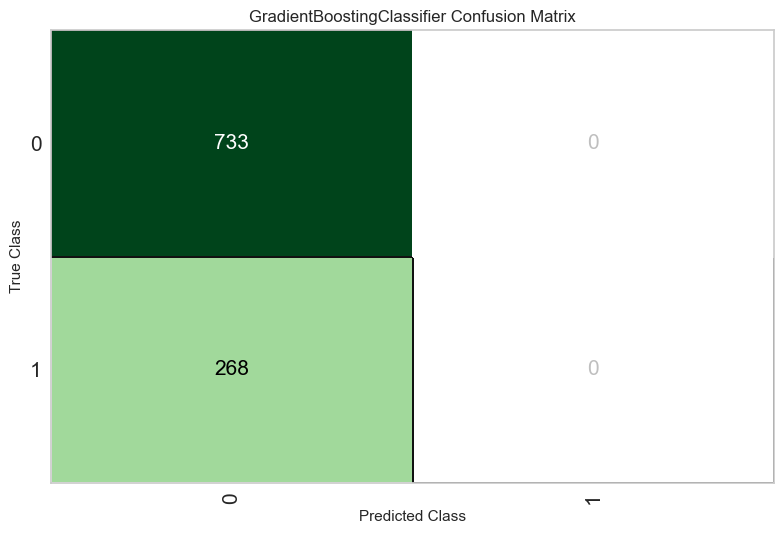

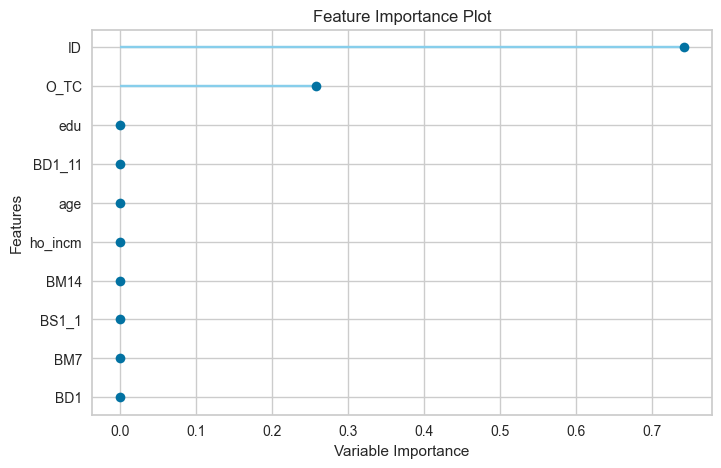

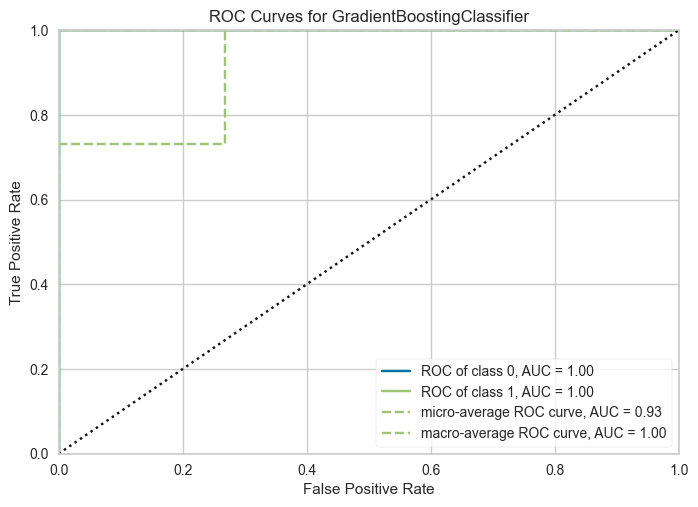

In [21]:
from pycaret.classification import *

for model_name, model in zip(['LightGBM','XGBoost','RandomForest'], best_models):
    # Confusion Matrix
    plot_model(model, plot='confusion_matrix')

    # Feature Importance
    plot_model(model, plot='feature')

    # ROC Curve
    plot_model(model, plot='auc')



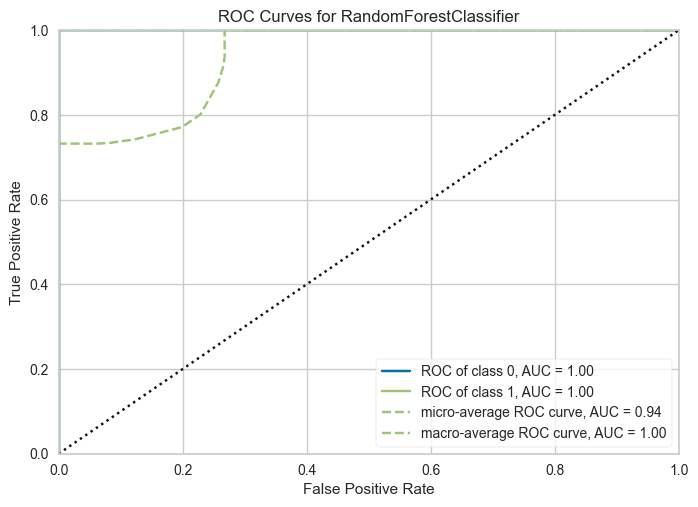

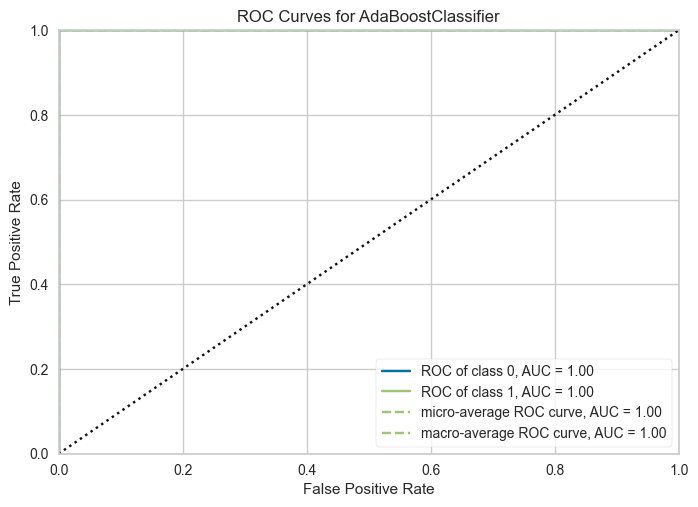

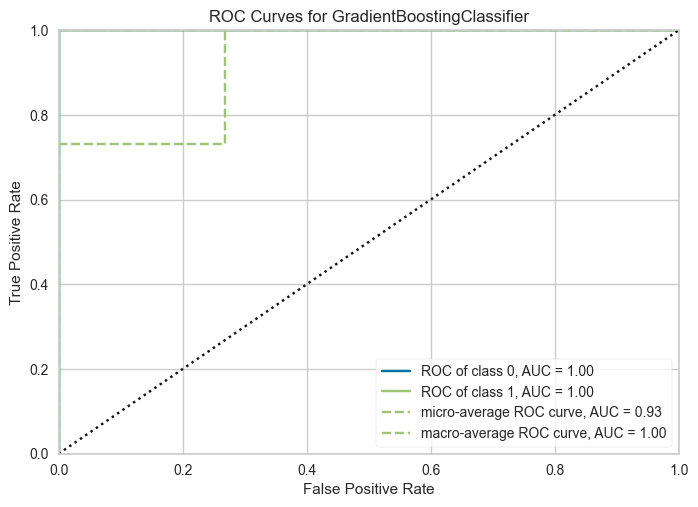

In [22]:
plot_model(best_models[0], plot='auc')  # LightGBM
plot_model(best_models[1], plot='auc')  # XGBoost
plot_model(best_models[2], plot='auc') 